In [1]:
import torch
import torchvision
import sklearn
import matplotlib
import seaborn

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None'}")

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [2]:
import numpy as np
import random

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

print(f"Seed set to {SEED}")

Seed set to 42


In [3]:
import torchvision.datasets as datasets
import torchvision.transforms as transforms

# Basic transform for now — just resize + convert to tensor
# (we'll add proper normalization once we check the pretrained model's expected stats)
transform = transforms.Compose([
    transforms.ToTensor()
])

# This downloads EuroSAT RGB (~90MB) to Colab's local storage
dataset = datasets.EuroSAT(root='./data', download=True, transform=transform)

print(f"Total images: {len(dataset)}")
print(f"Classes: {dataset.classes}")
print(f"Number of classes: {len(dataset.classes)}")


100%|██████████| 94.3M/94.3M [00:01<00:00, 77.7MB/s]


Total images: 27000
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Number of classes: 10


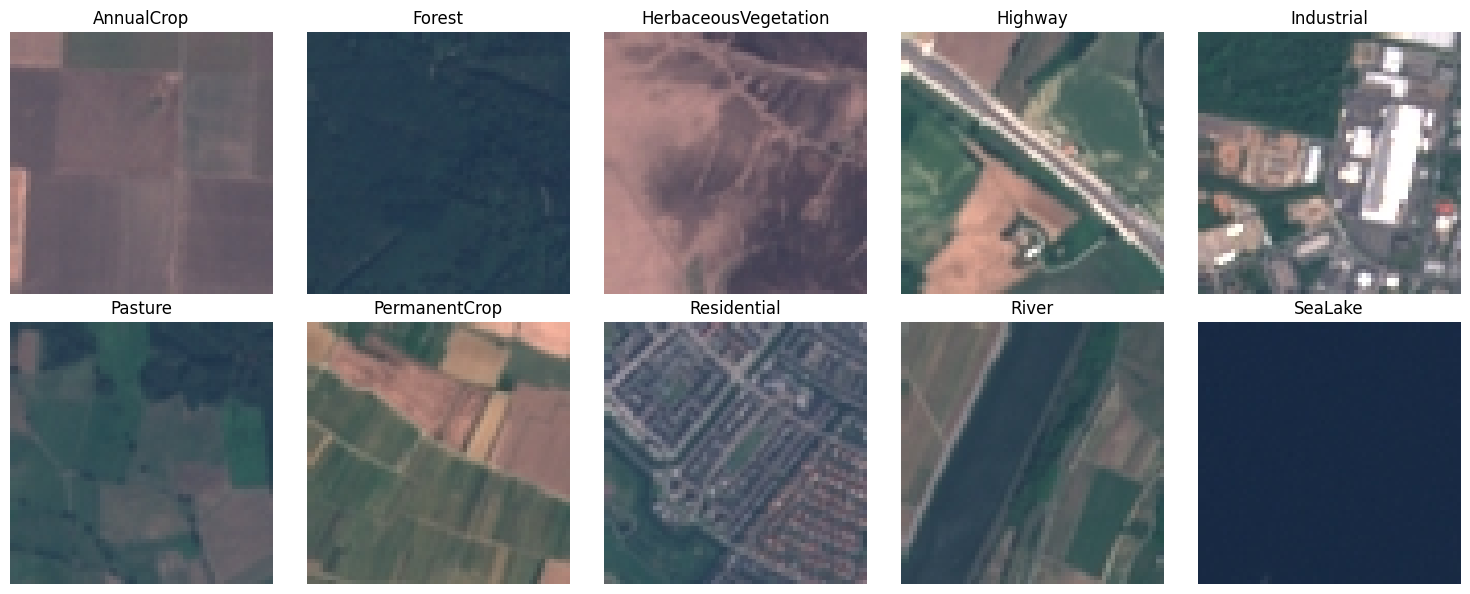

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

seen_classes = {}
for img, label in dataset:
    class_name = dataset.classes[label]
    if class_name not in seen_classes:
        seen_classes[class_name] = img
    if len(seen_classes) == 10:
        break

for idx, (class_name, img) in enumerate(seen_classes.items()):
    # img is a tensor (C, H, W) — convert to (H, W, C) for display
    img_display = img.permute(1, 2, 0).numpy()
    axes[idx].imshow(img_display)
    axes[idx].set_title(class_name)
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

In [5]:
from collections import Counter

# Count how many images belong to each class
labels = [label for _, label in dataset]
counts = Counter(labels)

for class_idx, count in sorted(counts.items()):
    class_name = dataset.classes[class_idx]
    print(f"{class_name}: {count} images")

AnnualCrop: 3000 images
Forest: 3000 images
HerbaceousVegetation: 3000 images
Highway: 2500 images
Industrial: 2500 images
Pasture: 2000 images
PermanentCrop: 2500 images
Residential: 3000 images
River: 2500 images
SeaLake: 3000 images


In [6]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

# Get indices and labels
indices = list(range(len(dataset)))
labels = [label for _, label in dataset]

# First split: 70% train, 30% temp (which becomes val+test)
train_idx, temp_idx, train_labels, temp_labels = train_test_split(
    indices, labels,
    test_size=0.30,
    stratify=labels,
    random_state=SEED
)

# Second split: divide the 30% temp into 15% val, 15% test (i.e. 50/50 of temp)
val_idx, test_idx, val_labels, test_labels = train_test_split(
    temp_idx, temp_labels,
    test_size=0.50,
    stratify=temp_labels,
    random_state=SEED
)

train_dataset = Subset(dataset, train_idx)
val_dataset = Subset(dataset, val_idx)
test_dataset = Subset(dataset, test_idx)

print(f"Train: {len(train_dataset)} images")
print(f"Val: {len(val_dataset)} images")
print(f"Test: {len(test_dataset)} images")

Train: 18900 images
Val: 4050 images
Test: 4050 images


In [7]:
import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights

# Load ResNet50 pretrained on ImageNet
weights = ResNet50_Weights.IMAGENET1K_V2
model = resnet50(weights=weights)

# Freeze all layers first
for param in model.parameters():
    param.requires_grad = False

# Unfreeze the last block (layer4) and the classification head
for param in model.layer4.parameters():
    param.requires_grad = True

# Replace the final fully connected layer: 2048 -> 10 classes (instead of 1000)
num_classes = 10
model.fc = nn.Linear(model.fc.in_features, num_classes)
# New layers are trainable by default, so model.fc params already require_grad=True

# Move model to GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

# Sanity check: count trainable vs frozen params
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Trainable params: {trainable:,} / {total:,} ({100*trainable/total:.1f}%)")
print(f"Device: {device}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 131MB/s]


Trainable params: 14,985,226 / 23,528,522 (63.7%)
Device: cuda


In [8]:
from torch.utils.data import DataLoader

batch_size = 32

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

print(f"Train batches: {len(train_loader)}")
print(f"Val batches: {len(val_loader)}")
print(f"Test batches: {len(test_loader)}")

Train batches: 591
Val batches: 127
Test batches: 127


In [9]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4)

print("Loss: CrossEntropyLoss")
print("Optimizer: Adam, lr=1e-4")

Loss: CrossEntropyLoss
Optimizer: Adam, lr=1e-4


In [10]:
import time

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total

def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
    return running_loss / total, correct / total

num_epochs = 15
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_loss = float('inf')

for epoch in range(num_epochs):
    start = time.time()
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)
    elapsed = time.time() - start

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), 'best_model.pth')
        marker = " <- saved (best so far)"
    else:
        marker = ""

    print(f"Epoch {epoch+1}/{num_epochs} ({elapsed:.1f}s) - "
          f"train_loss: {train_loss:.4f}, train_acc: {train_acc:.4f} - "
          f"val_loss: {val_loss:.4f}, val_acc: {val_acc:.4f}{marker}")

Epoch 1/15 (26.5s) - train_loss: 0.5683, train_acc: 0.8258 - val_loss: 0.1833, val_acc: 0.9398 <- saved (best so far)
Epoch 2/15 (25.0s) - train_loss: 0.1755, train_acc: 0.9419 - val_loss: 0.1600, val_acc: 0.9481 <- saved (best so far)
Epoch 3/15 (24.5s) - train_loss: 0.1027, train_acc: 0.9659 - val_loss: 0.1501, val_acc: 0.9491 <- saved (best so far)
Epoch 4/15 (25.6s) - train_loss: 0.0755, train_acc: 0.9750 - val_loss: 0.1553, val_acc: 0.9519
Epoch 5/15 (25.2s) - train_loss: 0.0553, train_acc: 0.9824 - val_loss: 0.1719, val_acc: 0.9514
Epoch 6/15 (25.9s) - train_loss: 0.0475, train_acc: 0.9854 - val_loss: 0.1640, val_acc: 0.9538
Epoch 7/15 (26.6s) - train_loss: 0.0389, train_acc: 0.9879 - val_loss: 0.1571, val_acc: 0.9541
Epoch 8/15 (25.7s) - train_loss: 0.0332, train_acc: 0.9895 - val_loss: 0.1717, val_acc: 0.9541
Epoch 9/15 (25.0s) - train_loss: 0.0280, train_acc: 0.9903 - val_loss: 0.1683, val_acc: 0.9595
Epoch 10/15 (25.1s) - train_loss: 0.0244, train_acc: 0.9925 - val_loss: 0.17

In [11]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

best_model = resnet50(weights=None)
best_model.fc = nn.Linear(best_model.fc.in_features, num_classes)
best_model.load_state_dict(torch.load('best_model.pth'))
best_model = best_model.to(device)
best_model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = best_model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

test_acc = (all_preds == all_labels).mean()
print(f"Test accuracy: {test_acc:.4f}\n")
print(classification_report(all_labels, all_preds, target_names=dataset.classes))



Test accuracy: 0.9568

                      precision    recall  f1-score   support

          AnnualCrop       0.95      0.94      0.95       450
              Forest       0.97      0.95      0.96       450
HerbaceousVegetation       0.92      0.96      0.94       450
             Highway       0.96      0.96      0.96       375
          Industrial       0.98      0.98      0.98       375
             Pasture       0.95      0.92      0.94       300
       PermanentCrop       0.94      0.90      0.92       375
         Residential       0.98      0.99      0.98       450
               River       0.94      0.97      0.95       375
             SeaLake       0.96      0.98      0.97       450

            accuracy                           0.96      4050
           macro avg       0.96      0.96      0.96      4050
        weighted avg       0.96      0.96      0.96      4050



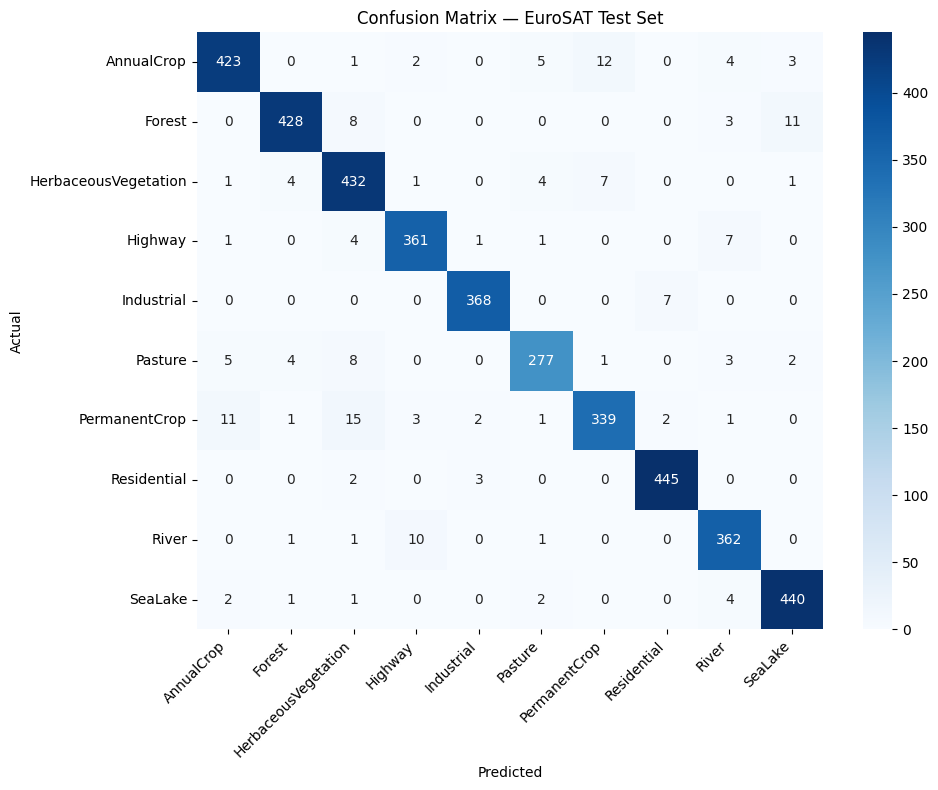

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=dataset.classes, yticklabels=dataset.classes)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix — EuroSAT Test Set')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [13]:
import ee

ee.Authenticate()
ee.Initialize(project='eurostatpaper')

In [14]:
!pip install geemap -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 88.5 MB/s eta 0:00:00


In [15]:
import geemap

# Shifted south to sit entirely within tile 43PDS — avoids the tile-seam issue
region = ee.Geometry.Rectangle([74.317, 14.800, 74.783, 15.250])

year_a_start, year_a_end = '2018-01-01', '2018-03-31'
year_b_start, year_b_end = '2024-01-01', '2024-03-31'

def mask_clouds(image):
    qa = image.select('QA60')
    cloud_bit_mask = 1 << 10
    cirrus_bit_mask = 1 << 11
    mask = qa.bitwiseAnd(cloud_bit_mask).eq(0).And(qa.bitwiseAnd(cirrus_bit_mask).eq(0))
    return image.updateMask(mask)

def get_composite(start_date, end_date, region):
    collection = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                  .filterBounds(region)
                  .filterDate(start_date, end_date)
                  .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
                  .map(mask_clouds))
    composite = collection.median().clip(region)
    return composite, collection.size()

image_a, count_a = get_composite(year_a_start, year_a_end, region)
image_b, count_b = get_composite(year_b_start, year_b_end, region)

print(f"Year A passes: {count_a.getInfo()}")
print(f"Year B passes: {count_b.getInfo()}")

Year A passes: 12
Year B passes: 30


In [16]:
vis_params = {
    'bands': ['B4', 'B3', 'B2'],
    'min': 0,
    'max': 3000
}

Map2 = geemap.Map(center=[15.02, 74.55], zoom=11)
Map2.addLayer(image_a, vis_params, 'Year A (2018)')
Map2.addLayer(image_b, vis_params, 'Year B (2024)')
Map2.addLayerControl()
Map2

Map(center=[15.02, 74.55], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

In [17]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [18]:
task_a = ee.batch.Export.image.toDrive(
    image=image_a,
    description='year_a_2018',
    folder='eurosat_deforestation',
    fileNamePrefix='year_a_2018',
    region=region,
    scale=10,
    crs='EPSG:4326',
    maxPixels=1e9
)
task_a.start()

task_b = ee.batch.Export.image.toDrive(
    image=image_b,
    description='year_b_2024',
    folder='eurosat_deforestation',
    fileNamePrefix='year_b_2024',
    region=region,
    scale=10,
    crs='EPSG:4326',
    maxPixels=1e9
)
task_b.start()

print("Both export tasks started.")

Both export tasks started.


In [19]:
import time

def check_task_status(task, name):
    status = task.status()
    print(f"{name}: {status['state']}")
    return status['state']

# Check both tasks
status_a = check_task_status(task_a, 'Year A (2018)')
status_b = check_task_status(task_b, 'Year B (2024)')

Year A (2018): READY
Year B (2024): READY


In [20]:
image_a_rgb = image_a.select(['B4', 'B3', 'B2'])
image_b_rgb = image_b.select(['B4', 'B3', 'B2'])

task_a2 = ee.batch.Export.image.toDrive(
    image=image_a_rgb,
    description='year_a_2018_rgb',
    folder='eurosat_deforestation',
    fileNamePrefix='year_a_2018_rgb',
    region=region,
    scale=10,
    crs='EPSG:4326',
    maxPixels=1e9
)
task_a2.start()

task_b2 = ee.batch.Export.image.toDrive(
    image=image_b_rgb,
    description='year_b_2024_rgb',
    folder='eurosat_deforestation',
    fileNamePrefix='year_b_2024_rgb',
    region=region,
    scale=10,
    crs='EPSG:4326',
    maxPixels=1e9
)
task_b2.start()

print("RGB-only export tasks started.")

RGB-only export tasks started.


In [21]:
status_a2 = check_task_status(task_a2, 'Year A RGB (2018)')
status_b2 = check_task_status(task_b2, 'Year B RGB (2024)')

Year A RGB (2018): READY
Year B RGB (2024): READY


In [22]:
!pip install rasterio -q

In [23]:
import os

# List what's actually in your Drive under MyDrive
for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for f in files:
        if 'year_a' in f or 'year_b' in f:
            print(os.path.join(root, f))

/content/drive/MyDrive/eurosat_deforestation/year_a_2018_rgb.tif
/content/drive/MyDrive/eurosat_deforestation/year_b_2024_rgb.tif
/content/drive/MyDrive/eurosat_deforestation/predictions_year_a_2018.csv
/content/drive/MyDrive/eurosat_deforestation/predictions_year_b_2024.csv
/content/drive/MyDrive/eurosat_deforestation/year_b_2024_l1c_rgb.tif
/content/drive/MyDrive/eurosat_deforestation/year_a_2018_l1c_rgb.tif
/content/drive/MyDrive/eurosat_deforestation/year_a_2018-0000000000-0000000000.tif
/content/drive/MyDrive/eurosat_deforestation/year_a_2018-0000000000-0000004608.tif
/content/drive/MyDrive/eurosat_deforestation/year_a_2018-0000004608-0000000000.tif
/content/drive/MyDrive/eurosat_deforestation/year_a_2018-0000004608-0000004608.tif
/content/drive/MyDrive/eurosat_deforestation/year_b_2024-0000000000-0000000000.tif
/content/drive/MyDrive/eurosat_deforestation/year_b_2024-0000000000-0000004608.tif
/content/drive/MyDrive/eurosat_deforestation/year_b_2024-0000004608-0000000000.tif
/cont

In [24]:
def run_inference(tiles, model, device, batch_size=64):
    model.eval()
    results = []

    for i in range(0, len(tiles), batch_size):
        batch = tiles[i:i+batch_size]
        # Stack tiles into one tensor batch, scale 0-255 -> 0-1
        batch_tensors = torch.stack([
            torch.from_numpy(tile).float() / 255.0 for tile, row, col in batch
        ]).to(device)

        with torch.no_grad():
            outputs = model(batch_tensors)
            probs = torch.softmax(outputs, dim=1)
            confidences, predictions = torch.max(probs, dim=1)

        for j, (tile, row, col) in enumerate(batch):
            results.append({
                'row': row,
                'col': col,
                'predicted_class': dataset.classes[predictions[j].item()],
                'confidence': confidences[j].item()
            })

    return results

In [25]:
def get_composite_l1c(start_date, end_date, region):
    collection = (ee.ImageCollection('COPERNICUS/S2_HARMONIZED')  # L1C/TOA — matches EuroSAT's actual source
                  .filterBounds(region)
                  .filterDate(start_date, end_date)
                  .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
                  .map(mask_clouds))
    composite = collection.median().clip(region)
    return composite, collection.size()

image_a_l1c, count_a_l1c = get_composite_l1c(year_a_start, year_a_end, region)
image_b_l1c, count_b_l1c = get_composite_l1c(year_b_start, year_b_end, region)

print(f"Year A (L1C) passes: {count_a_l1c.getInfo()}")
print(f"Year B (L1C) passes: {count_b_l1c.getInfo()}")

image_a_l1c_rgb = image_a_l1c.select(['B4', 'B3', 'B2'])
image_b_l1c_rgb = image_b_l1c.select(['B4', 'B3', 'B2'])

task_a3 = ee.batch.Export.image.toDrive(
    image=image_a_l1c_rgb, description='year_a_2018_l1c_rgb',
    folder='eurosat_deforestation', fileNamePrefix='year_a_2018_l1c_rgb',
    region=region, scale=10, crs='EPSG:4326', maxPixels=1e9
)
task_a3.start()

task_b3 = ee.batch.Export.image.toDrive(
    image=image_b_l1c_rgb, description='year_b_2024_l1c_rgb',
    folder='eurosat_deforestation', fileNamePrefix='year_b_2024_l1c_rgb',
    region=region, scale=10, crs='EPSG:4326', maxPixels=1e9
)
task_b3.start()

print("L1C RGB export tasks started.")

Year A (L1C) passes: 25
Year B (L1C) passes: 30
L1C RGB export tasks started.


In [26]:
status_a3 = check_task_status(task_a3, 'Year A L1C')
status_b3 = check_task_status(task_b3, 'Year B L1C')

Year A L1C: READY
Year B L1C: READY


In [27]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for f in files:
        if 'l1c' in f.lower():
            full_path = os.path.join(root, f)
            print(f"{full_path}  —  modified: {os.path.getmtime(full_path)}")

/content/drive/MyDrive/eurosat_deforestation/year_b_2024_l1c_rgb.tif  —  modified: 1785065107.0
/content/drive/MyDrive/eurosat_deforestation/year_a_2018_l1c_rgb.tif  —  modified: 1785065136.0


In [28]:
def scale_to_uint8_joint(img, low_pct=2, high_pct=98):
    img_filled = np.nan_to_num(img, nan=0.0)
    low = np.percentile(img_filled, low_pct)
    high = np.percentile(img_filled, high_pct)
    img_clipped = np.clip(img_filled, low, high)
    img_scaled = ((img_clipped - low) / (high - low + 1e-6) * 255).astype(np.uint8)
    return img_scaled

In [29]:
sample_indices = np.random.choice(len(dataset), 200, replace=False)
sample_imgs = torch.stack([dataset[idx][0] for idx in sample_indices])  # values 0-1

target_mean = sample_imgs.mean().item() * 255
target_std = sample_imgs.std().item() * 255
print(f"Target mean: {target_mean:.2f}, Target std: {target_std:.2f}")

Target mean: 98.32, Target std: 41.52


In [30]:
TILE_SIZE = 64

def tile_image(img_array, tile_size=64):
    bands, height, width = img_array.shape
    n_rows = height // tile_size
    n_cols = width // tile_size
    tiles = []
    for row in range(n_rows):
        for col in range(n_cols):
            y0 = row * tile_size
            x0 = col * tile_size
            tile = img_array[:, y0:y0+tile_size, x0:x0+tile_size]
            tiles.append((tile, row, col))
    return tiles

def run_inference(tiles, model, device, batch_size=64):
    model.eval()
    results = []
    for i in range(0, len(tiles), batch_size):
        batch = tiles[i:i+batch_size]
        batch_tensors = torch.stack([
            torch.from_numpy(tile).float() / 255.0 for tile, row, col in batch
        ]).to(device)
        with torch.no_grad():
            outputs = model(batch_tensors)
            probs = torch.softmax(outputs, dim=1)
            confidences, predictions = torch.max(probs, dim=1)
        for j, (tile, row, col) in enumerate(batch):
            results.append({
                'row': row,
                'col': col,
                'predicted_class': dataset.classes[predictions[j].item()],
                'confidence': confidences[j].item()
            })
    return results

print("Functions redefined and ready.")

Functions redefined and ready.


In [31]:
def get_ndwi(start_date, end_date, region):
    collection = (ee.ImageCollection('COPERNICUS/S2_HARMONIZED')
                  .filterBounds(region)
                  .filterDate(start_date, end_date)
                  .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
                  .map(mask_clouds))
    composite = collection.median().clip(region)
    ndwi = composite.normalizedDifference(['B3', 'B8']).rename('NDWI')
    return ndwi

ndwi_a = get_ndwi(year_a_start, year_a_end, region)
ndwi_b = get_ndwi(year_b_start, year_b_end, region)

task_ndwi_a = ee.batch.Export.image.toDrive(
    image=ndwi_a, description='ndwi_year_a_2018',
    folder='eurosat_deforestation', fileNamePrefix='ndwi_year_a_2018',
    region=region, scale=10, crs='EPSG:4326', maxPixels=1e9
)
task_ndwi_a.start()

task_ndwi_b = ee.batch.Export.image.toDrive(
    image=ndwi_b, description='ndwi_year_b_2024',
    folder='eurosat_deforestation', fileNamePrefix='ndwi_year_b_2024',
    region=region, scale=10, crs='EPSG:4326', maxPixels=1e9
)
task_ndwi_b.start()

print("NDWI export tasks started.")

NDWI export tasks started.


In [32]:
status_ndwi_a = check_task_status(task_ndwi_a, 'NDWI Year A')
status_ndwi_b = check_task_status(task_ndwi_b, 'NDWI Year B')

NDWI Year A: READY
NDWI Year B: READY


In [33]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for f in files:
        if 'ndwi' in f.lower():
            print(os.path.join(root, f))

/content/drive/MyDrive/eurosat_deforestation/ndwi_year_a_2018.tif
/content/drive/MyDrive/eurosat_deforestation/ndwi_year_b_2024.tif
/content/drive/MyDrive/eurosat_deforestation/ndwi_year_a_2018_v2.tif
/content/drive/MyDrive/eurosat_deforestation/ndwi_year_b_2024_v2.tif


In [34]:
import rasterio

In [35]:
path_ndwi_a = '/content/drive/MyDrive/eurosat_deforestation/ndwi_year_a_2018.tif'
path_ndwi_b = '/content/drive/MyDrive/eurosat_deforestation/ndwi_year_b_2024.tif'

with rasterio.open(path_ndwi_a) as src:
    ndwi_arr_a = src.read(1)
    print(f"NDWI Year A shape: {ndwi_arr_a.shape}")

with rasterio.open(path_ndwi_b) as src:
    ndwi_arr_b = src.read(1)
    print(f"NDWI Year B shape: {ndwi_arr_b.shape}")

NDWI Year A shape: (5012, 5188)
NDWI Year B shape: (5012, 5188)


In [36]:
for name in ['tiles_a_final', 'results_a_final', 'df_a_final', 'best_model', 'dataset']:
    print(name, 'EXISTS' if name in dir() else 'MISSING')

tiles_a_final MISSING
results_a_final MISSING
df_a_final MISSING
best_model EXISTS
dataset EXISTS


In [37]:
TILE_SIZE = 64

def tile_image(img_array, tile_size=64):
    bands, height, width = img_array.shape
    n_rows = height // tile_size
    n_cols = width // tile_size
    tiles = []
    for row in range(n_rows):
        for col in range(n_cols):
            y0 = row * tile_size
            x0 = col * tile_size
            tile = img_array[:, y0:y0+tile_size, x0:x0+tile_size]
            tiles.append((tile, row, col))
    return tiles

def run_inference(tiles, model, device, batch_size=64):
    model.eval()
    results = []
    for i in range(0, len(tiles), batch_size):
        batch = tiles[i:i+batch_size]
        batch_tensors = torch.stack([
            torch.from_numpy(tile).float() / 255.0 for tile, row, col in batch
        ]).to(device)
        with torch.no_grad():
            outputs = model(batch_tensors)
            probs

In [38]:
print('img_a_matched' in dir())

False


In [39]:
path_a_l1c = '/content/drive/MyDrive/eurosat_deforestation/year_a_2018_l1c_rgb.tif'
path_b_l1c = '/content/drive/MyDrive/eurosat_deforestation/year_b_2024_l1c_rgb.tif'

with rasterio.open(path_a_l1c) as src:
    img_a_l1c = src.read()
with rasterio.open(path_b_l1c) as src:
    img_b_l1c = src.read()

print(f"Year A shape: {img_a_l1c.shape}, Year B shape: {img_b_l1c.shape}")

Year A shape: (3, 5012, 5188), Year B shape: (3, 5012, 5188)


In [40]:
sample_indices = np.random.choice(len(dataset), 200, replace=False)
sample_imgs = torch.stack([dataset[idx][0] for idx in sample_indices])
target_mean = sample_imgs.mean().item() * 255
target_std = sample_imgs.std().item() * 255

def scale_to_match_stats(img, target_mean, target_std, low_pct=1, high_pct=99):
    img_filled = np.nan_to_num(img, nan=0.0)
    low = np.percentile(img_filled, low_pct)
    high = np.percentile(img_filled, high_pct)
    img_clipped = np.clip(img_filled, low, high)
    current_mean = img_clipped.mean()
    current_std = img_clipped.std()
    img_matched = (img_clipped - current_mean) / (current_std + 1e-6) * target_std + target_mean
    img_matched = np.clip(img_matched, 0, 255).astype(np.uint8)
    return img_matched

img_a_matched = scale_to_match_stats(img_a_l1c, target_mean, target_std)
img_b_matched = scale_to_match_stats(img_b_l1c, target_mean, target_std)

print(f"Year A matched mean (0-1): {img_a_matched.mean()/255:.3f}")
print(f"Year B matched mean (0-1): {img_b_matched.mean()/255:.3f}")
print(f"Target: {target_mean/255:.3f}")

Year A matched mean (0-1): 0.364
Year B matched mean (0-1): 0.364
Target: 0.366


In [41]:
def run_inference(tiles, model, device, batch_size=64):
    model.eval()
    results = []
    for i in range(0, len(tiles), batch_size):
        batch = tiles[i:i+batch_size]
        batch_tensors = torch.stack([
            torch.from_numpy(tile).float() / 255.0 for tile, row, col in batch
        ]).to(device)
        with torch.no_grad():
            outputs = model(batch_tensors)
            probs = torch.softmax(outputs, dim=1)
            confidences, predictions = torch.max(probs, dim=1)
        for j, (tile, row, col) in enumerate(batch):
            results.append({
                'row': row,
                'col': col,
                'predicted_class': dataset.classes[predictions[j].item()],
                'confidence': confidences[j].item()
            })
    return results

print("run_inference redefined.")

run_inference redefined.


In [42]:
print('img_b_matched' in dir())

True


In [43]:
# 1. Core imports
import torch
import torch.nn as nn
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torchvision.models import resnet50
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 2. Dataset (needed for dataset.classes)
transform = transforms.Compose([transforms.ToTensor()])
dataset = datasets.EuroSAT(root='./data', download=True, transform=transform)
num_classes = len(dataset.classes)

# 3. Mount Drive
from google.colab import drive
drive.mount('/content/drive')

print("Core setup done.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Core setup done.


In [44]:
import os
for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for f in files:
        if 'best_model' in f.lower() or f.endswith('.pth'):
            print(os.path.join(root, f))

/content/drive/MyDrive/eurosat_deforestation/best_model.pth


In [45]:
import shutil
shutil.copy('best_model.pth', '/content/drive/MyDrive/eurosat_deforestation/best_model.pth')

best_model = resnet50(weights=None)
best_model.fc = nn.Linear(best_model.fc.in_features, num_classes)
best_model.load_state_dict(torch.load('best_model.pth'))
best_model = best_model.to(device)
best_model.eval()
print("Model trained, saved to Drive, and loaded as best_model.")

Model trained, saved to Drive, and loaded as best_model.


In [46]:
# Load best model from Drive
best_model = resnet50(weights=None)
best_model.fc = nn.Linear(best_model.fc.in_features, num_classes)
best_model.load_state_dict(torch.load('/content/drive/MyDrive/eurosat_deforestation/best_model.pth'))
best_model = best_model.to(device)
best_model.eval()
print("Model loaded.")

# Load L1C RGB imagery
path_a_l1c = '/content/drive/MyDrive/eurosat_deforestation/year_a_2018_l1c_rgb.tif'
path_b_l1c = '/content/drive/MyDrive/eurosat_deforestation/year_b_2024_l1c_rgb.tif'

with rasterio.open(path_a_l1c) as src:
    img_a_l1c = src.read()
with rasterio.open(path_b_l1c) as src:
    img_b_l1c = src.read()
print(f"L1C imagery loaded: {img_a_l1c.shape}, {img_b_l1c.shape}")

# Load NDWI
path_ndwi_a = '/content/drive/MyDrive/eurosat_deforestation/ndwi_year_a_2018.tif'
path_ndwi_b = '/content/drive/MyDrive/eurosat_deforestation/ndwi_year_b_2024.tif'

with rasterio.open(path_ndwi_a) as src:
    ndwi_arr_a = src.read(1)
with rasterio.open(path_ndwi_b) as src:
    ndwi_arr_b = src.read(1)
print(f"NDWI loaded: {ndwi_arr_a.shape}, {ndwi_arr_b.shape}")

# Moment-match brightness to training data
sample_indices = np.random.choice(len(dataset), 200, replace=False)
sample_imgs = torch.stack([dataset[idx][0] for idx in sample_indices])
target_mean = sample_imgs.mean().item() * 255
target_std = sample_imgs.std().item() * 255

def scale_to_match_stats(img, target_mean, target_std, low_pct=1, high_pct=99):
    img_filled = np.nan_to_num(img, nan=0.0)
    low = np.percentile(img_filled, low_pct)
    high = np.percentile(img_filled, high_pct)
    img_clipped = np.clip(img_filled, low, high)
    current_mean = img_clipped.mean()
    current_std = img_clipped.std()
    img_matched = (img_clipped - current_mean) / (current_std + 1e-6) * target_std + target_mean
    return np.clip(img_matched, 0, 255).astype(np.uint8)

img_a_matched = scale_to_match_stats(img_a_l1c, target_mean, target_std)
img_b_matched = scale_to_match_stats(img_b_l1c, target_mean, target_std)
print(f"Brightness matched: A={img_a_matched.mean()/255:.3f}, B={img_b_matched.mean()/255:.3f}, target={target_mean/255:.3f}")

Model loaded.
L1C imagery loaded: (3, 5012, 5188), (3, 5012, 5188)
NDWI loaded: (5012, 5188), (5012, 5188)
Brightness matched: A=0.371, B=0.371, target=0.373


In [47]:
TILE_SIZE = 64

def tile_image(img_array, tile_size=64):
    bands, height, width = img_array.shape
    n_rows = height // tile_size
    n_cols = width // tile_size
    tiles = []
    for row in range(n_rows):
        for col in range(n_cols):
            y0, x0 = row * tile_size, col * tile_size
            tile = img_array[:, y0:y0+tile_size, x0:x0+tile_size]
            tiles.append((tile, row, col))
    return tiles

def run_inference(tiles, model, device, batch_size=64):
    model.eval()
    results = []
    for i in range(0, len(tiles), batch_size):
        batch = tiles[i:i+batch_size]
        batch_tensors = torch.stack([
            torch.from_numpy(tile).float() / 255.0 for tile, row, col in batch
        ]).to(device)
        with torch.no_grad():
            outputs = model(batch_tensors)
            probs = torch.softmax(outputs, dim=1)
            confidences, predictions = torch.max(probs, dim=1)
        for j, (tile, row, col) in enumerate(batch):
            results.append({
                'row': row, 'col': col,
                'predicted_class': dataset.classes[predictions[j].item()],
                'confidence': confidences[j].item()
            })
    return results

def get_tile_ndwi_means(ndwi_array, tile_size=64):
    height, width = ndwi_array.shape
    n_rows, n_cols = height // tile_size, width // tile_size
    tile_means = {}
    for row in range(n_rows):
        for col in range(n_cols):
            y0, x0 = row * tile_size, col * tile_size
            tile_means[(row, col)] = np.nanmean(ndwi_array[y0:y0+tile_size, x0:x0+tile_size])
    return tile_means

def correct_sealake(row):
    if row['predicted_class'] == 'SeaLake':
        return 'SeaLake' if row['ndwi'] > 0 else 'Forest_or_Land (NDWI-corrected)'
    return row['predicted_class']

# Year A
tiles_a_final = tile_image(img_a_matched, TILE_SIZE)
results_a_final = run_inference(tiles_a_final, best_model, device)
df_a_final = pd.DataFrame(results_a_final)
ndwi_means_a = get_tile_ndwi_means(ndwi_arr_a, TILE_SIZE)
df_a_final['ndwi'] = df_a_final.apply(lambda r: ndwi_means_a[(r['row'], r['col'])], axis=1)
df_a_final['corrected_class'] = df_a_final.apply(correct_sealake, axis=1)

# Year B
tiles_b_final = tile_image(img_b_matched, TILE_SIZE)
results_b_final = run_inference(tiles_b_final, best_model, device)
df_b_final = pd.DataFrame(results_b_final)
ndwi_means_b = get_tile_ndwi_means(ndwi_arr_b, TILE_SIZE)
df_b_final['ndwi'] = df_b_final.apply(lambda r: ndwi_means_b[(r['row'], r['col'])], axis=1)
df_b_final['corrected_class'] = df_b_final.apply(correct_sealake, axis=1)

print(f"Year A: {len(df_a_final)} tiles, Year B: {len(df_b_final)} tiles — rebuilt and NDWI-corrected")

Year A: 6318 tiles, Year B: 6318 tiles — rebuilt and NDWI-corrected


In [48]:
comparison_conf = df_a_final.merge(
    df_b_final, on=['row', 'col'], suffixes=('_2018', '_2024')
)
comparison_conf['changed'] = comparison_conf['corrected_class_2018'] != comparison_conf['corrected_class_2024']

CONFIDENCE_THRESHOLD_STRICT = 0.90
confident_mask_strict = (comparison_conf['confidence_2018'] >= CONFIDENCE_THRESHOLD_STRICT) & \
                         (comparison_conf['confidence_2024'] >= CONFIDENCE_THRESHOLD_STRICT)
clean_mask = (comparison_conf['corrected_class_2018'] != 'Forest_or_Land (NDWI-corrected)') & \
             (comparison_conf['corrected_class_2024'] != 'Forest_or_Land (NDWI-corrected)')

filtered_strict = comparison_conf[confident_mask_strict & clean_mask]

forest_to_other_strict = filtered_strict[
    (filtered_strict['corrected_class_2018'] == 'Forest') &
    (filtered_strict['corrected_class_2024'] != 'Forest')
]
print(f"Forest→other candidates (0.90 confidence, before clustering): {len(forest_to_other_strict)}")
print(forest_to_other_strict[['row', 'col', 'corrected_class_2024']])

Forest→other candidates (0.90 confidence, before clustering): 2
      row  col  corrected_class_2024
4082   50   32  HerbaceousVegetation
5599   69   10  HerbaceousVegetation


In [49]:
import os
path = '/content/drive/MyDrive/eurosat_deforestation/best_model.pth'
print(f"Checkpoint exists: {os.path.exists(path)}")
print(f"Last modified: {os.path.getmtime(path)}")

Checkpoint exists: True
Last modified: 1785837786.0


In [50]:
def has_adjacent_match(row, col, target_rows_cols_set):
    neighbors = [(row+dr, col+dc) for dr in [-1,0,1] for dc in [-1,0,1] if not (dr==0 and dc==0)]
    return any(n in target_rows_cols_set for n in neighbors)

candidate_locations = set(zip(forest_to_other_strict['row'], forest_to_other_strict['col']))
forest_to_other_strict = forest_to_other_strict.copy()
forest_to_other_strict['has_neighbor'] = forest_to_other_strict.apply(
    lambda r: has_adjacent_match(r['row'], r['col'], candidate_locations), axis=1
)
print(forest_to_other_strict[['row', 'col', 'corrected_class_2024', 'has_neighbor']])

      row  col  corrected_class_2024  has_neighbor
4082   50   32  HerbaceousVegetation         False
5599   69   10  HerbaceousVegetation         False


In [51]:
CONFIDENCE_THRESHOLD = 0.75
confident_mask = (comparison_conf['confidence_2018'] >= CONFIDENCE_THRESHOLD) & \
                 (comparison_conf['confidence_2024'] >= CONFIDENCE_THRESHOLD)

filtered = comparison_conf[confident_mask & clean_mask]

forest_to_other_clean = filtered[
    (filtered['corrected_class_2018'] == 'Forest') &
    (filtered['corrected_class_2024'] != 'Forest')
].copy()

print(f"Candidates at 0.75 confidence: {len(forest_to_other_clean)}")

candidate_locations_75 = set(zip(forest_to_other_clean['row'], forest_to_other_clean['col']))

forest_to_other_clean['has_neighbor'] = forest_to_other_clean.apply(
    lambda r: has_adjacent_match(r['row'], r['col'], candidate_locations_75), axis=1
)

clustered_75 = forest_to_other_clean[forest_to_other_clean['has_neighbor']]

print(f"Candidates with at least one adjacent match: {len(clustered_75)} / {len(forest_to_other_clean)}")
print(clustered_75[['row', 'col', 'corrected_class_2024']])

Candidates at 0.75 confidence: 11
Candidates with at least one adjacent match: 0 / 11
Empty DataFrame
Columns: [row, col, corrected_class_2024]
Index: []


In [52]:
import geemap

# New region: shifted toward the Yellapur forest-agriculture boundary, still within tile 43PDS
region_v2 = ee.Geometry.Rectangle([74.550, 14.750, 75.016, 15.200])

Map5 = geemap.Map(center=[14.97, 74.78], zoom=10)
Map5.addLayer(region_v2, {'color': 'red'}, 'Yellapur Periphery Region')
Map5

Map(center=[14.97, 74.78], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

In [53]:
def mask_clouds(image):
    qa = image.select('QA60')
    cloud_bit_mask = 1 << 10
    cirrus_bit_mask = 1 << 11
    mask = qa.bitwiseAnd(cloud_bit_mask).eq(0).And(qa.bitwiseAnd(cirrus_bit_mask).eq(0))
    return image.updateMask(mask)

def get_composite_l1c(start_date, end_date, region):
    collection = (ee.ImageCollection('COPERNICUS/S2_HARMONIZED')
                  .filterBounds(region)
                  .filterDate(start_date, end_date)
                  .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
                  .map(mask_clouds))
    composite = collection.median().clip(region)
    return composite, collection.size()

year_a_start, year_a_end = '2018-01-01', '2018-03-31'
year_b_start, year_b_end = '2024-01-01', '2024-03-31'

region = region_v2
image_a, count_a = get_composite_l1c(year_a_start, year_a_end, region)
image_b, count_b = get_composite_l1c(year_b_start, year_b_end, region)

print(f"Year A passes: {count_a.getInfo()}")
print(f"Year B passes: {count_b.getInfo()}")

Year A passes: 49
Year B passes: 61


In [54]:
image_a_rgb = image_a.select(['B4', 'B3', 'B2'])
image_b_rgb = image_b.select(['B4', 'B3', 'B2'])

ndwi_a = image_a.normalizedDifference(['B3', 'B8']).rename('NDWI')
ndwi_b = image_b.normalizedDifference(['B3', 'B8']).rename('NDWI')

exports = [
    (image_a_rgb, 'year_a_2018_v2_rgb'),
    (image_b_rgb, 'year_b_2024_v2_rgb'),
    (ndwi_a, 'ndwi_year_a_2018_v2'),
    (ndwi_b, 'ndwi_year_b_2024_v2'),
]

tasks = []
for img, name in exports:
    task = ee.batch.Export.image.toDrive(
        image=img,
        description=name,
        folder='eurosat_deforestation',
        fileNamePrefix=name,
        region=region,
        scale=10,
        crs='EPSG:4326',
        maxPixels=1e9
    )
    task.start()
    tasks.append((task, name))

print("All 4 exports started:", [name for _, name in tasks])

All 4 exports started: ['year_a_2018_v2_rgb', 'year_b_2024_v2_rgb', 'ndwi_year_a_2018_v2', 'ndwi_year_b_2024_v2']


In [55]:
for task, name in tasks:
    print(f"{name}: {task.status()['state']}")

year_a_2018_v2_rgb: READY
year_b_2024_v2_rgb: READY
ndwi_year_a_2018_v2: READY
ndwi_year_b_2024_v2: READY


In [56]:
for name in ['best_model', 'dataset', 'region_v2', 'image_a', 'image_b', 'tasks']:
    print(name, 'EXISTS' if name in dir() else 'MISSING')

best_model EXISTS
dataset EXISTS
region_v2 EXISTS
image_a EXISTS
image_b EXISTS
tasks EXISTS


In [57]:
for task, name in tasks:
    print(f"{name}: {task.status()['state']}")

year_a_2018_v2_rgb: READY
year_b_2024_v2_rgb: READY
ndwi_year_a_2018_v2: READY
ndwi_year_b_2024_v2: READY


In [58]:
import os
for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for f in files:
        if '_v2' in f:
            print(os.path.join(root, f))

/content/drive/MyDrive/eurosat_deforestation/year_b_2024_v2_rgb.tif
/content/drive/MyDrive/eurosat_deforestation/ndwi_year_a_2018_v2.tif
/content/drive/MyDrive/eurosat_deforestation/ndwi_year_b_2024_v2.tif
/content/drive/MyDrive/eurosat_deforestation/year_a_2018_v2_rgb.tif
/content/drive/MyDrive/eurosat_deforestation/gfw_loss_v2.tif


In [59]:
path_a_rgb = '/content/drive/MyDrive/eurosat_deforestation/year_a_2018_v2_rgb.tif'
path_b_rgb = '/content/drive/MyDrive/eurosat_deforestation/year_b_2024_v2_rgb.tif'
path_ndwi_a_v2 = '/content/drive/MyDrive/eurosat_deforestation/ndwi_year_a_2018_v2.tif'
path_ndwi_b_v2 = '/content/drive/MyDrive/eurosat_deforestation/ndwi_year_b_2024_v2.tif'

with rasterio.open(path_a_rgb) as src:
    img_a_v2 = src.read()
with rasterio.open(path_b_rgb) as src:
    img_b_v2 = src.read()
with rasterio.open(path_ndwi_a_v2) as src:
    ndwi_arr_a_v2 = src.read(1)
with rasterio.open(path_ndwi_b_v2) as src:
    ndwi_arr_b_v2 = src.read(1)

print(f"Year A: {img_a_v2.shape}, Year B: {img_b_v2.shape}")
print(f"NDWI A: {ndwi_arr_a_v2.shape}, NDWI B: {ndwi_arr_b_v2.shape}")

Year A: (3, 5011, 5189), Year B: (3, 5011, 5189)
NDWI A: (5011, 5189), NDWI B: (5011, 5189)


In [60]:
def scale_to_match_stats(img, target_mean, target_std, low_pct=1, high_pct=99):
    img_filled = np.nan_to_num(img, nan=0.0)
    low = np.percentile(img_filled, low_pct)
    high = np.percentile(img_filled, high_pct)
    img_clipped = np.clip(img_filled, low, high)
    current_mean = img_clipped.mean()
    current_std = img_clipped.std()
    img_matched = (img_clipped - current_mean) / (current_std + 1e-6) * target_std + target_mean
    return np.clip(img_matched, 0, 255).astype(np.uint8)

print("Function defined.")

Function defined.


In [61]:
print('target_mean' in dir(), 'target_std' in dir())

True True


In [62]:
sample_indices = np.random.choice(len(dataset), 200, replace=False)
sample_imgs = torch.stack([dataset[idx][0] for idx in sample_indices])
target_mean = sample_imgs.mean().item() * 255
target_std = sample_imgs.std().item() * 255
print(f"target_mean: {target_mean:.2f}, target_std: {target_std:.2f}")

target_mean: 96.79, target_std: 41.13


In [63]:
from google.colab import drive
drive.mount('/content/drive')

import ee
ee.Authenticate()
ee.Initialize(project='eurostatpaper')

print("Drive and Earth Engine ready.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive and Earth Engine ready.


In [64]:
import torch
import torch.nn as nn
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torchvision.models import resnet50
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
import geemap

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Dataset (for dataset.classes and brightness target stats)
transform = transforms.Compose([transforms.ToTensor()])
dataset = datasets.EuroSAT(root='./data', download=True, transform=transform)
num_classes = len(dataset.classes)

# Load the canonical trained model from Drive
best_model = resnet50(weights=None)
best_model.fc = nn.Linear(best_model.fc.in_features, num_classes)
best_model.load_state_dict(torch.load('/content/drive/MyDrive/eurosat_deforestation/best_model.pth'))
best_model = best_model.to(device)
best_model.eval()

# Target brightness stats (for matching real imagery to training data)
sample_indices = np.random.choice(len(dataset), 200, replace=False)
sample_imgs = torch.stack([dataset[idx][0] for idx in sample_indices])
target_mean = sample_imgs.mean().item() * 255
target_std = sample_imgs.std().item() * 255

TILE_SIZE = 64

def mask_clouds(image):
    qa = image.select('QA60')
    cloud_bit_mask = 1 << 10
    cirrus_bit_mask = 1 << 11
    mask = qa.bitwiseAnd(cloud_bit_mask).eq(0).And(qa.bitwiseAnd(cirrus_bit_mask).eq(0))
    return image.updateMask(mask)

def get_composite_l1c(start_date, end_date, region):
    collection = (ee.ImageCollection('COPERNICUS/S2_HARMONIZED')
                  .filterBounds(region)
                  .filterDate(start_date, end_date)
                  .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
                  .map(mask_clouds))
    composite = collection.median().clip(region)
    return composite, collection.size()

def scale_to_match_stats(img, target_mean, target_std, low_pct=1, high_pct=99):
    img_filled = np.nan_to_num(img, nan=0.0)
    low = np.percentile(img_filled, low_pct)
    high = np.percentile(img_filled, high_pct)
    img_clipped = np.clip(img_filled, low, high)
    current_mean = img_clipped.mean()
    current_std = img_clipped.std()
    img_matched = (img_clipped - current_mean) / (current_std + 1e-6) * target_std + target_mean
    return np.clip(img_matched, 0, 255).astype(np.uint8)

def tile_image(img_array, tile_size=64):
    bands, height, width = img_array.shape
    n_rows, n_cols = height // tile_size, width // tile_size
    tiles = []
    for row in range(n_rows):
        for col in range(n_cols):
            y0, x0 = row * tile_size, col * tile_size
            tiles.append((img_array[:, y0:y0+tile_size, x0:x0+tile_size], row, col))
    return tiles

def run_inference(tiles, model, device, batch_size=64):
    model.eval()
    results = []
    for i in range(0, len(tiles), batch_size):
        batch = tiles[i:i+batch_size]
        batch_tensors = torch.stack([
            torch.from_numpy(tile).float() / 255.0 for tile, row, col in batch
        ]).to(device)
        with torch.no_grad():
            outputs = model(batch_tensors)
            probs = torch.softmax(outputs, dim=1)
            confidences, predictions = torch.max(probs, dim=1)
        for j, (tile, row, col) in enumerate(batch):
            results.append({
                'row': row, 'col': col,
                'predicted_class': dataset.classes[predictions[j].item()],
                'confidence': confidences[j].item()
            })
    return results

def get_tile_ndwi_means(ndwi_array, tile_size=64):
    height, width = ndwi_array.shape
    n_rows, n_cols = height // tile_size, width // tile_size
    tile_means = {}
    for row in range(n_rows):
        for col in range(n_cols):
            y0, x0 = row * tile_size, col * tile_size
            tile_means[(row, col)] = np.nanmean(ndwi_array[y0:y0+tile_size, x0:x0+tile_size])
    return tile_means

def correct_sealake(row):
    if row['predicted_class'] == 'SeaLake':
        return 'SeaLake' if row['ndwi'] > 0 else 'Forest_or_Land (NDWI-corrected)'
    return row['predicted_class']

def has_adjacent_match(row, col, target_rows_cols_set):
    neighbors = [(row+dr, col+dc) for dr in [-1,0,1] for dc in [-1,0,1] if not (dr==0 and dc==0)]
    return any(n in target_rows_cols_set for n in neighbors)

year_a_start, year_a_end = '2018-01-01', '2018-03-31'
year_b_start, year_b_end = '2024-01-01', '2024-03-31'

print(f"Setup complete. Target brightness: {target_mean/255:.3f}. Model, dataset, and all functions loaded.")

Setup complete. Target brightness: 0.385. Model, dataset, and all functions loaded.


In [65]:
path_a_rgb = '/content/drive/MyDrive/eurosat_deforestation/year_a_2018_v2_rgb.tif'
path_b_rgb = '/content/drive/MyDrive/eurosat_deforestation/year_b_2024_v2_rgb.tif'
path_ndwi_a_v2 = '/content/drive/MyDrive/eurosat_deforestation/ndwi_year_a_2018_v2.tif'
path_ndwi_b_v2 = '/content/drive/MyDrive/eurosat_deforestation/ndwi_year_b_2024_v2.tif'

with rasterio.open(path_a_rgb) as src:
    img_a_v2 = src.read()
with rasterio.open(path_b_rgb) as src:
    img_b_v2 = src.read()
with rasterio.open(path_ndwi_a_v2) as src:
    ndwi_arr_a_v2 = src.read(1)
with rasterio.open(path_ndwi_b_v2) as src:
    ndwi_arr_b_v2 = src.read(1)

print(f"Year A: {img_a_v2.shape}, Year B: {img_b_v2.shape}")

Year A: (3, 5011, 5189), Year B: (3, 5011, 5189)


In [66]:
img_a_v2_matched = scale_to_match_stats(img_a_v2, target_mean, target_std)
img_b_v2_matched = scale_to_match_stats(img_b_v2, target_mean, target_std)

tiles_a_v2 = tile_image(img_a_v2_matched, TILE_SIZE)
tiles_b_v2 = tile_image(img_b_v2_matched, TILE_SIZE)

results_a_v2 = run_inference(tiles_a_v2, best_model, device)
results_b_v2 = run_inference(tiles_b_v2, best_model, device)

df_a_v2 = pd.DataFrame(results_a_v2)
df_b_v2 = pd.DataFrame(results_b_v2)

ndwi_means_a_v2 = get_tile_ndwi_means(ndwi_arr_a_v2, TILE_SIZE)
ndwi_means_b_v2 = get_tile_ndwi_means(ndwi_arr_b_v2, TILE_SIZE)

df_a_v2['ndwi'] = df_a_v2.apply(lambda r: ndwi_means_a_v2[(r['row'], r['col'])], axis=1)
df_b_v2['ndwi'] = df_b_v2.apply(lambda r: ndwi_means_b_v2[(r['row'], r['col'])], axis=1)

df_a_v2['corrected_class'] = df_a_v2.apply(correct_sealake, axis=1)
df_b_v2['corrected_class'] = df_b_v2.apply(correct_sealake, axis=1)

print(f"Year A tiles: {len(df_a_v2)}")
print(df_a_v2['corrected_class'].value_counts())
print(f"\nYear B tiles: {len(df_b_v2)}")
print(df_b_v2['corrected_class'].value_counts())

Year A tiles: 6318
corrected_class
HerbaceousVegetation               3253
Forest                              963
Forest_or_Land (NDWI-corrected)     758
PermanentCrop                       475
Pasture                             370
AnnualCrop                          162
River                               156
Residential                         100
Industrial                           33
SeaLake                              27
Highway                              21
Name: count, dtype: int64

Year B tiles: 6318
corrected_class
HerbaceousVegetation               2253
Forest                             1627
Forest_or_Land (NDWI-corrected)     864
PermanentCrop                       434
Pasture                             391
Residential                         270
River                               182
AnnualCrop                          171
Industrial                           68
Highway                              32
SeaLake                              26
Name: count, dtype: int

In [67]:
comparison_v2 = df_a_v2.merge(df_b_v2, on=['row', 'col'], suffixes=('_2018', '_2024'))
comparison_v2['changed'] = comparison_v2['corrected_class_2018'] != comparison_v2['corrected_class_2024']

print(f"Total tiles: {len(comparison_v2)}")
print(f"Changed (no filtering): {comparison_v2['changed'].sum()} ({100*comparison_v2['changed'].mean():.1f}%)")

CONFIDENCE_THRESHOLD = 0.75
confident_mask_v2 = (comparison_v2['confidence_2018'] >= CONFIDENCE_THRESHOLD) & \
                    (comparison_v2['confidence_2024'] >= CONFIDENCE_THRESHOLD)
clean_mask_v2 = (comparison_v2['corrected_class_2018'] != 'Forest_or_Land (NDWI-corrected)') & \
                (comparison_v2['corrected_class_2024'] != 'Forest_or_Land (NDWI-corrected)')

filtered_v2 = comparison_v2[confident_mask_v2 & clean_mask_v2]
print(f"\nAfter confidence + ambiguity filtering: {len(filtered_v2)} tiles")
print(f"Changed among these: {filtered_v2['changed'].sum()} ({100*filtered_v2['changed'].mean():.1f}%)")

forest_to_other_v2 = filtered_v2[
    (filtered_v2['corrected_class_2018'] == 'Forest') &
    (filtered_v2['corrected_class_2024'] != 'Forest')
]
print(f"\nForest→other candidates: {len(forest_to_other_v2)}")
print(forest_to_other_v2['corrected_class_2024'].value_counts())

# Also check the reverse, given Forest count went up overall
other_to_forest_v2 = filtered_v2[
    (filtered_v2['corrected_class_2018'] != 'Forest') &
    (filtered_v2['corrected_class_2024'] == 'Forest')
]
print(f"\nOther→Forest candidates: {len(other_to_forest_v2)}")
print(other_to_forest_v2['corrected_class_2018'].value_counts())

Total tiles: 6318
Changed (no filtering): 3158 (50.0%)

After confidence + ambiguity filtering: 1740 tiles
Changed among these: 384 (22.1%)

Forest→other candidates: 27
corrected_class_2024
HerbaceousVegetation    16
Residential             10
AnnualCrop               1
Name: count, dtype: int64

Other→Forest candidates: 185
corrected_class_2018
HerbaceousVegetation    182
River                     2
Residential               1
Name: count, dtype: int64


In [68]:
candidate_locations_v2 = set(zip(forest_to_other_v2['row'], forest_to_other_v2['col']))

forest_to_other_v2 = forest_to_other_v2.copy()
forest_to_other_v2['has_neighbor'] = forest_to_other_v2.apply(
    lambda r: has_adjacent_match(r['row'], r['col'], candidate_locations_v2), axis=1
)

clustered_v2 = forest_to_other_v2[forest_to_other_v2['has_neighbor']]

print(f"Candidates with at least one adjacent match: {len(clustered_v2)} / {len(forest_to_other_v2)}")
print(clustered_v2[['row', 'col', 'corrected_class_2024']])

Candidates with at least one adjacent match: 2 / 27
      row  col  corrected_class_2024
4918   60   58  HerbaceousVegetation
5000   61   59  HerbaceousVegetation


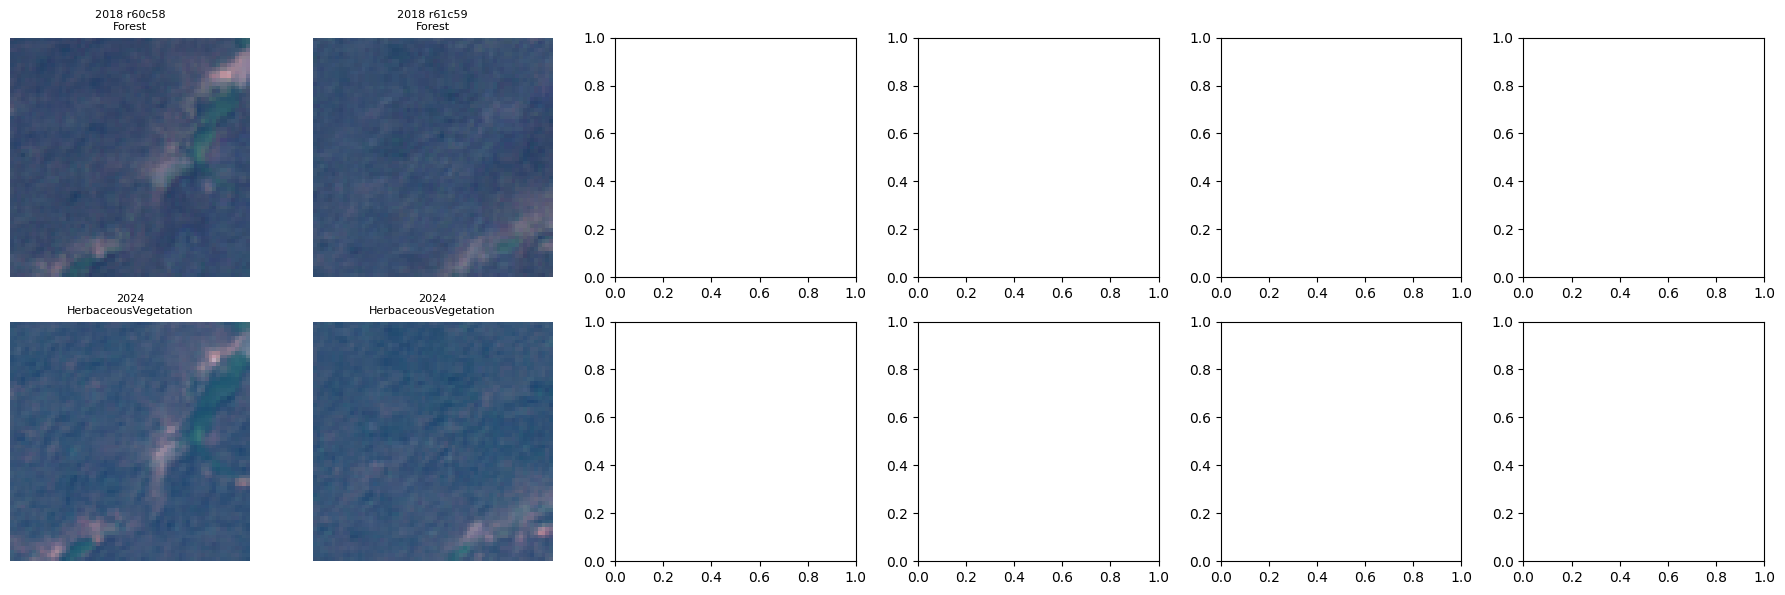

In [69]:
fig, axes = plt.subplots(2, 6, figsize=(18, 6))

for i, (_, r) in enumerate(clustered_v2.iterrows()):
    row, col = r['row'], r['col']
    n_cols_grid = img_a_v2_matched.shape[2] // TILE_SIZE
    idx = row * n_cols_grid + col

    tile_2018 = tiles_a_v2[idx][0]
    tile_2024 = tiles_b_v2[idx][0]

    axes[0, i].imshow(tile_2018.transpose(1, 2, 0))
    axes[0, i].set_title(f'2018 r{row}c{col}\nForest', fontsize=8)
    axes[0, i].axis('off')

    axes[1, i].imshow(tile_2024.transpose(1, 2, 0))
    axes[1, i].set_title(f'2024\n{r["corrected_class_2024"]}', fontsize=8)
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

In [70]:
# Step 0 — check what's still alive
for name in ['df_a_v2', 'df_b_v2', 'tiles_a_v2', 'tiles_b_v2', 'img_a_v2_matched', 'has_adjacent_match']:
    print(name, 'EXISTS' if name in dir() else 'MISSING')

df_a_v2 EXISTS
df_b_v2 EXISTS
tiles_a_v2 EXISTS
tiles_b_v2 EXISTS
img_a_v2_matched EXISTS
has_adjacent_match EXISTS


In [71]:
# Step 1 — rebuild the comparison with an ASYMMETRIC confidence requirement
# 2018 side must be HIGH confidence (this is where "already had a bare patch" was sneaking in)
# 2024 side stays looser, since we care more about catching real new change than being strict there
comparison_v2 = df_a_v2.merge(df_b_v2, on=['row', 'col'], suffixes=('_2018', '_2024'))
comparison_v2['changed'] = comparison_v2['corrected_class_2018'] != comparison_v2['corrected_class_2024']

CONF_2018_STRICT = 0.90
CONF_2024 = 0.75

confident_mask_asym = (comparison_v2['confidence_2018'] >= CONF_2018_STRICT) & \
                       (comparison_v2['confidence_2024'] >= CONF_2024)
clean_mask_asym = (comparison_v2['corrected_class_2018'] != 'Forest_or_Land (NDWI-corrected)') & \
                   (comparison_v2['corrected_class_2024'] != 'Forest_or_Land (NDWI-corrected)')

filtered_asym = comparison_v2[confident_mask_asym & clean_mask_asym]

forest_to_other_asym = filtered_asym[
    (filtered_asym['corrected_class_2018'] == 'Forest') &
    (filtered_asym['corrected_class_2024'] != 'Forest')
].copy()

print(f"Forest→other candidates (2018 conf≥0.90, 2024 conf≥0.75): {len(forest_to_other_asym)}")
print(forest_to_other_asym[['row', 'col', 'corrected_class_2024']])

# Step 2 — spatial clustering on this stricter set
candidate_locations_asym = set(zip(forest_to_other_asym['row'], forest_to_other_asym['col']))
forest_to_other_asym['has_neighbor'] = forest_to_other_asym.apply(
    lambda r: has_adjacent_match(r['row'], r['col'], candidate_locations_asym), axis=1
)
clustered_asym = forest_to_other_asym[forest_to_other_asym['has_neighbor']]

print(f"\nClustered candidates: {len(clustered_asym)} / {len(forest_to_other_asym)}")
print(clustered_asym[['row', 'col', 'corrected_class_2024']])

Forest→other candidates (2018 conf≥0.90, 2024 conf≥0.75): 14
      row  col  corrected_class_2024
2615   32   23           Residential
2713   33   40           Residential
2873   35   38           Residential
3630   44   66  HerbaceousVegetation
3691   45   46  HerbaceousVegetation
4018   49   49           Residential
4089   50   39           Residential
4264   52   52           Residential
4313   53   20  HerbaceousVegetation
4457   55    2  HerbaceousVegetation
4740   58   42           Residential
4918   60   58  HerbaceousVegetation
5300   65   35  HerbaceousVegetation
5535   68   27  HerbaceousVegetation

Clustered candidates: 0 / 14
Empty DataFrame
Columns: [row, col, corrected_class_2024]
Index: []


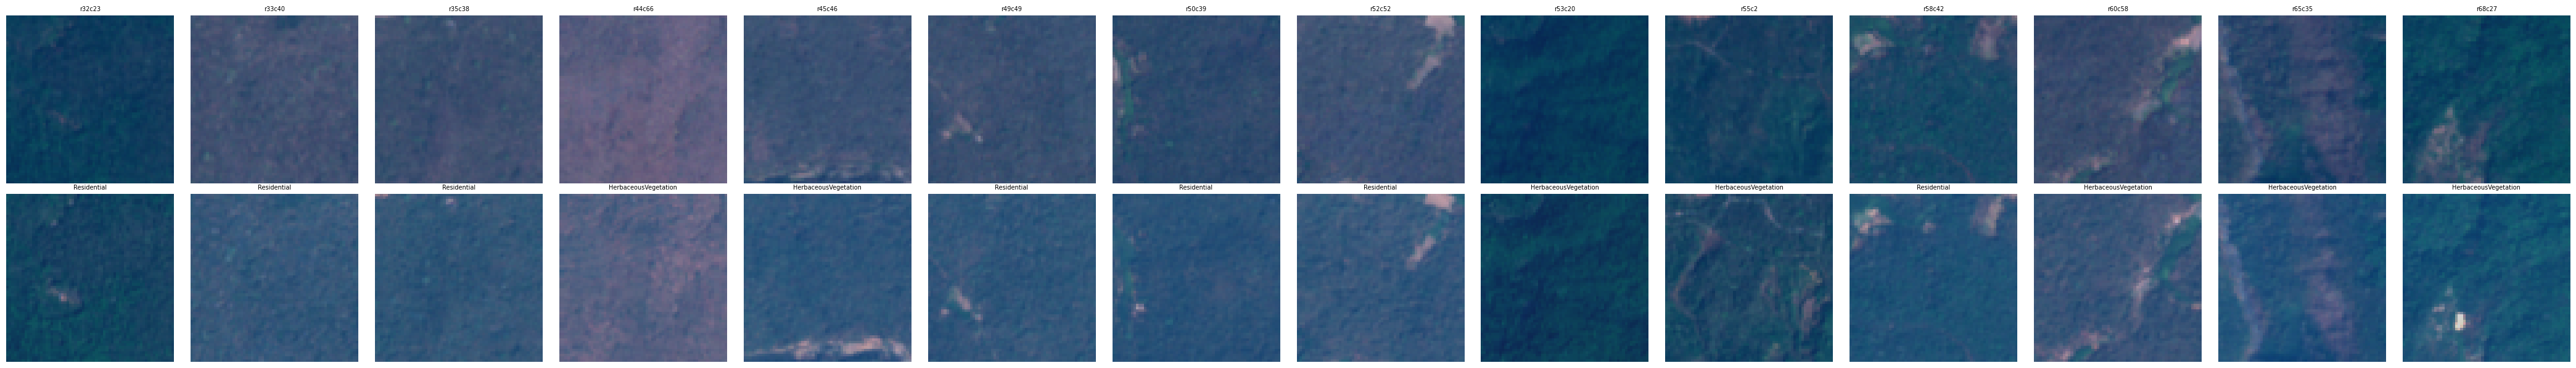

In [72]:
fig, axes = plt.subplots(2, len(forest_to_other_asym), figsize=(3*len(forest_to_other_asym), 6))

n_cols_grid = img_a_v2_matched.shape[2] // TILE_SIZE

for i, (_, r) in enumerate(forest_to_other_asym.iterrows()):
    row, col = r['row'], r['col']
    idx = row * n_cols_grid + col

    tile_2018 = tiles_a_v2[idx][0]
    tile_2024 = tiles_b_v2[idx][0]

    axes[0, i].imshow(tile_2018.transpose(1, 2, 0))
    axes[0, i].set_title(f'r{row}c{col}', fontsize=7)
    axes[0, i].axis('off')

    axes[1, i].imshow(tile_2024.transpose(1, 2, 0))
    axes[1, i].set_title(f'{r["corrected_class_2024"]}', fontsize=7)
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

In [73]:
gfw = ee.Image('UMD/hansen/global_forest_change_2023_v1_11')

# lossyear: pixel value 1-23 means loss detected in year 2000+value; 0 means no loss detected
loss_year = gfw.select('lossyear').clip(region_v2)
tree_cover_2000 = gfw.select('treecover2000').clip(region_v2)

# Filter to loss that happened specifically in your comparison window: 2018-2024
# lossyear encoding: 18 = 2018, 24 = 2024
loss_in_window = loss_year.gte(18).And(loss_year.lte(24))

# Only count it as loss if there was meaningful tree cover to begin with (standard GFW practice: >30% canopy)
significant_forest = tree_cover_2000.gte(30)
real_loss = loss_in_window.And(significant_forest)

# Count how many 10m pixels show loss in this window, within your region
pixel_count = real_loss.reduceRegion(
    reducer=ee.Reducer.sum(),
    geometry=region_v2,
    scale=10,
    maxPixels=1e9
)

print("GFW-detected forest loss pixels (2018-2024, >30% canopy):", pixel_count.getInfo())

GFW-detected forest loss pixels (2018-2024, >30% canopy): {'lossyear': 15022.619607843135}


In [74]:
task_gfw = ee.batch.Export.image.toDrive(
    image=real_loss.toByte(),  # convert boolean mask to a simple 0/1 byte image
    description='gfw_loss_v2',
    folder='eurosat_deforestation',
    fileNamePrefix='gfw_loss_v2',
    region=region_v2,
    scale=10,
    crs='EPSG:4326',
    maxPixels=1e9
)
task_gfw.start()

print("GFW loss export started.")

GFW loss export started.


In [75]:
print(f"gfw_loss_v2: {task_gfw.status()['state']}")

gfw_loss_v2: READY


In [76]:
import os
for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for f in files:
        if 'gfw_loss' in f.lower():
            print(os.path.join(root, f))

/content/drive/MyDrive/eurosat_deforestation/gfw_loss_v2.tif


In [77]:
path_gfw = '/content/drive/MyDrive/eurosat_deforestation/gfw_loss_v2.tif'  # adjust if the search above shows a different path

with rasterio.open(path_gfw) as src:
    gfw_arr = src.read(1)

print(f"GFW loss array shape: {gfw_arr.shape}")
print(f"Total loss pixels: {gfw_arr.sum()}")
print(f"Total loss hectares: {gfw_arr.sum() * 100 / 10000:.1f}")

GFW loss array shape: (5011, 5189)
Total loss pixels: 14978
Total loss hectares: 149.8


In [78]:
def get_tile_loss_fraction(gfw_array, tile_size=64):
    height, width = gfw_array.shape
    n_rows, n_cols = height // tile_size, width // tile_size
    fractions = {}
    for row in range(n_rows):
        for col in range(n_cols):
            y0, x0 = row * tile_size, col * tile_size
            tile = gfw_array[y0:y0+tile_size, x0:x0+tile_size]
            fractions[(row, col)] = tile.mean()  # fraction of pixels flagged as loss
    return fractions

gfw_tile_fractions = get_tile_loss_fraction(gfw_arr, TILE_SIZE)

# Attach to your comparison dataframe
comparison_v2['gfw_loss_fraction'] = comparison_v2.apply(
    lambda r: gfw_tile_fractions[(r['row'], r['col'])], axis=1
)

# How many tiles does GFW flag as having ANY loss?
print(f"Tiles with any GFW-flagged loss: {(comparison_v2['gfw_loss_fraction'] > 0).sum()} / {len(comparison_v2)}")
print(f"Tiles with >10% of area flagged: {(comparison_v2['gfw_loss_fraction'] > 0.10).sum()}")

# Distribution of loss fraction among tiles that have ANY loss
any_loss = comparison_v2[comparison_v2['gfw_loss_fraction'] > 0]
print(f"\nAmong tiles with loss, mean fraction of tile affected: {any_loss['gfw_loss_fraction'].mean():.3f}")
print(f"Median: {any_loss['gfw_loss_fraction'].median():.3f}")


Tiles with any GFW-flagged loss: 351 / 6318
Tiles with >10% of area flagged: 3

Among tiles with loss, mean fraction of tile affected: 0.010
Median: 0.006


In [79]:
# Define GFW ground truth: any tile with >0% loss counts as "GFW says changed"
# (could also test a higher bar like >5%, but let's start with GFW's own definition: any detected loss)
comparison_v2['gfw_flags_loss'] = comparison_v2['gfw_loss_fraction'] > 0

# Define your model's prediction: any tile that went from Forest (2018) to non-Forest (2024), unfiltered
comparison_v2['model_flags_loss'] = (comparison_v2['corrected_class_2018'] == 'Forest') & \
                                     (comparison_v2['corrected_class_2024'] != 'Forest')

tp = ((comparison_v2['gfw_flags_loss']) & (comparison_v2['model_flags_loss'])).sum()
fp = ((~comparison_v2['gfw_flags_loss']) & (comparison_v2['model_flags_loss'])).sum()
fn = ((comparison_v2['gfw_flags_loss']) & (~comparison_v2['model_flags_loss'])).sum()
tn = ((~comparison_v2['gfw_flags_loss']) & (~comparison_v2['model_flags_loss'])).sum()

print(f"True Positives (both flag loss): {tp}")
print(f"False Positives (model only): {fp}")
print(f"False Negatives (GFW only): {fn}")
print(f"True Negatives (neither): {tn}")

precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
agreement = (tp + tn) / len(comparison_v2)

print(f"\nPrecision (of model's flags, % actually GFW-confirmed): {precision:.3f}")
print(f"Recall (of GFW's flags, % your model caught): {recall:.3f}")
print(f"Overall agreement: {agreement:.3f}")

True Positives (both flag loss): 24
False Positives (model only): 344
False Negatives (GFW only): 327
True Negatives (neither): 5623

Precision (of model's flags, % actually GFW-confirmed): 0.065
Recall (of GFW's flags, % your model caught): 0.068
Overall agreement: 0.894


In [80]:
# A few real False Negatives: GFW confirms loss, your model missed it
fn_examples = comparison_v2[
    (comparison_v2['gfw_flags_loss']) & (~comparison_v2['model_flags_loss'])
].sort_values('gfw_loss_fraction', ascending=False).head(5)

print("Top 5 False Negatives (GFW loss fraction, model missed):")
print(fn_examples[['row', 'col', 'gfw_loss_fraction', 'corrected_class_2018', 'corrected_class_2024']])

# A few real False Positives: your model flagged it, GFW didn't
fp_examples = comparison_v2[
    (~comparison_v2['gfw_flags_loss']) & (comparison_v2['model_flags_loss'])
].sample(5, random_state=42)

print("\n5 False Positives (model flagged, GFW didn't):")
print(fp_examples[['row', 'col', 'corrected_class_2018', 'corrected_class_2024', 'confidence_2018', 'confidence_2024']])

Top 5 False Negatives (GFW loss fraction, model missed):
      row  col  gfw_loss_fraction             corrected_class_2018  \
3269   40   29           0.121582  Forest_or_Land (NDWI-corrected)   
6170   76   14           0.114502             HerbaceousVegetation   
6102   75   27           0.062988             HerbaceousVegetation   
3578   44   14           0.056152             HerbaceousVegetation   
5403   66   57           0.055908             HerbaceousVegetation   

                 corrected_class_2024  
3269  Forest_or_Land (NDWI-corrected)  
6170             HerbaceousVegetation  
6102             HerbaceousVegetation  
3578  Forest_or_Land (NDWI-corrected)  
5403                            River  

5 False Positives (model flagged, GFW didn't):
      row  col corrected_class_2018             corrected_class_2024  \
4896   60   36               Forest             HerbaceousVegetation   
4473   55   18               Forest             HerbaceousVegetation   
5182   63   79    

In [81]:
clean_mask_final = (comparison_v2['corrected_class_2018'] != 'Forest_or_Land (NDWI-corrected)') & \
                    (comparison_v2['corrected_class_2024'] != 'Forest_or_Land (NDWI-corrected)')

comparison_clean = comparison_v2[clean_mask_final].copy()

tp2 = ((comparison_clean['gfw_flags_loss']) & (comparison_clean['model_flags_loss'])).sum()
fp2 = ((~comparison_clean['gfw_flags_loss']) & (comparison_clean['model_flags_loss'])).sum()
fn2 = ((comparison_clean['gfw_flags_loss']) & (~comparison_clean['model_flags_loss'])).sum()
tn2 = ((~comparison_clean['gfw_flags_loss']) & (~comparison_clean['model_flags_loss'])).sum()

print(f"TP: {tp2}, FP: {fp2}, FN: {fn2}, TN: {tn2}")
precision2 = tp2 / (tp2 + fp2) if (tp2+fp2) > 0 else 0
recall2 = tp2 / (tp2 + fn2) if (tp2+fn2) > 0 else 0
print(f"Precision: {precision2:.3f}, Recall: {recall2:.3f}, Agreement: {(tp2+tn2)/len(comparison_clean):.3f}")

TP: 16, FP: 210, FN: 227, TN: 4516
Precision: 0.071, Recall: 0.066, Agreement: 0.912


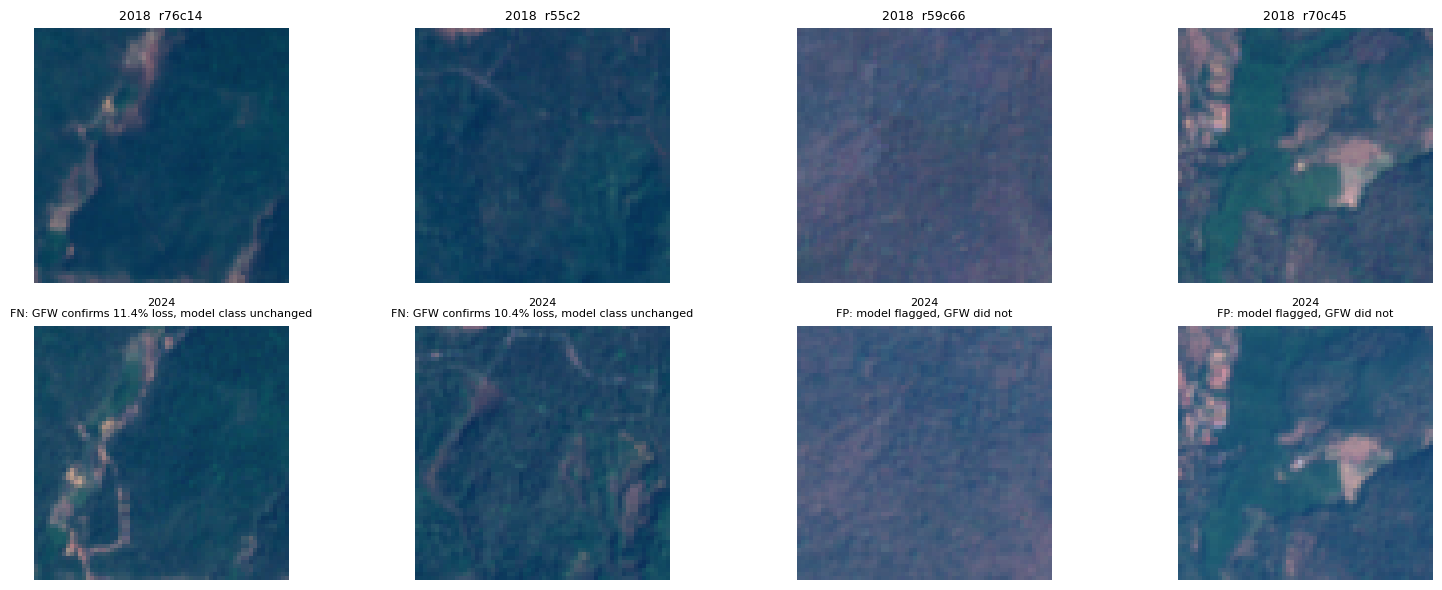

Saved to Drive: gap_analysis_examples.png


In [82]:
n_cols_grid = img_a_v2_matched.shape[2] // TILE_SIZE

examples_to_show = [
    (76, 14, 'FN: GFW confirms 11.4% loss, model class unchanged'),
    (55, 2, 'FN: GFW confirms 10.4% loss, model class unchanged'),
    (59, 66, 'FP: model flagged, GFW did not'),
    (70, 45, 'FP: model flagged, GFW did not'),
]

fig, axes = plt.subplots(2, len(examples_to_show), figsize=(4*len(examples_to_show), 6))

for i, (row, col, label) in enumerate(examples_to_show):
    idx = row * n_cols_grid + col
    tile_2018 = tiles_a_v2[idx][0]
    tile_2024 = tiles_b_v2[idx][0]

    axes[0, i].imshow(tile_2018.transpose(1, 2, 0))
    axes[0, i].set_title(f'2018  r{row}c{col}', fontsize=9)
    axes[0, i].axis('off')

    axes[1, i].imshow(tile_2024.transpose(1, 2, 0))
    axes[1, i].set_title(f'2024\n{label}', fontsize=8)
    axes[1, i].axis('off')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/eurosat_deforestation/gap_analysis_examples.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved to Drive: gap_analysis_examples.png")

In [82]:
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=dataset.classes, yticklabels=dataset.classes)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('')  # remove in-plot title; LaTeX caption handles this now
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/eurosat_deforestation/confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

Test accuracy: 0.9568


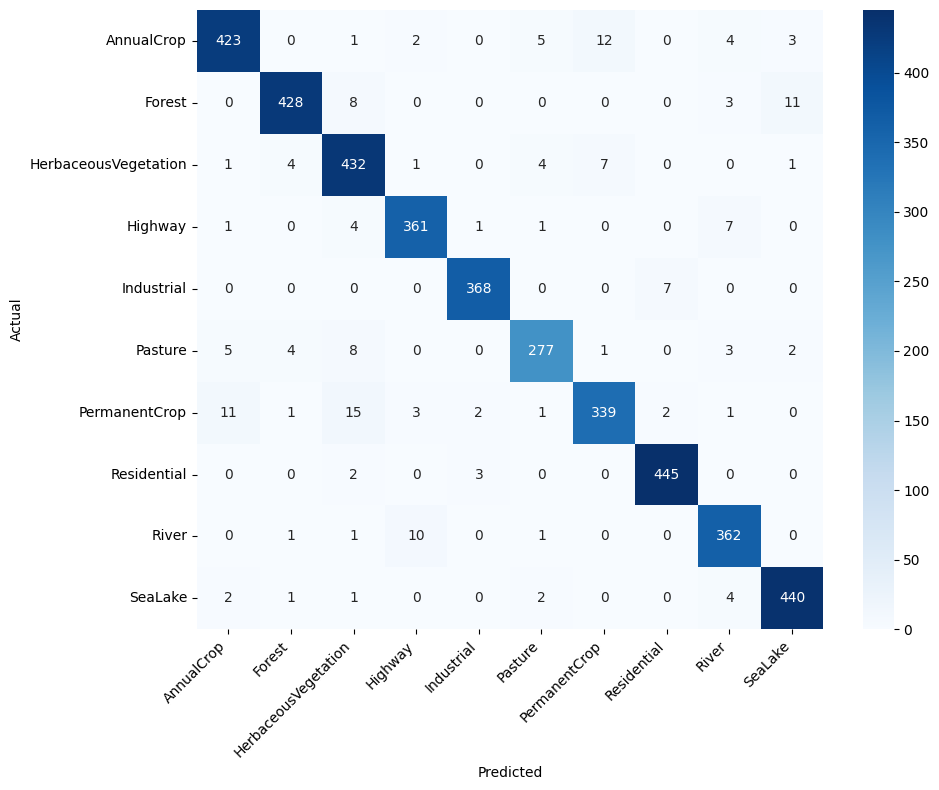

Saved: confusion_matrix.png


In [83]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset, DataLoader
from sklearn.metrics import confusion_matrix
import seaborn as sns

SEED = 42
indices = list(range(len(dataset)))
labels = [label for _, label in dataset]
train_idx, temp_idx, train_labels, temp_labels = train_test_split(
    indices, labels, test_size=0.30, stratify=labels, random_state=SEED)
val_idx, test_idx, val_labels, test_labels = train_test_split(
    temp_idx, temp_labels, test_size=0.50, stratify=temp_labels, random_state=SEED)

test_dataset = Subset(dataset, test_idx)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

all_preds, all_labels = [], []
best_model.eval()
with torch.no_grad():
    for images, labels_batch in test_loader:
        images = images.to(device)
        outputs = best_model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels_batch.numpy())

cm = confusion_matrix(all_labels, all_preds)
test_acc = (np.array(all_preds) == np.array(all_labels)).mean()
print(f"Test accuracy: {test_acc:.4f}")

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=dataset.classes, yticklabels=dataset.classes)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/eurosat_deforestation/confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

print("Saved: confusion_matrix.png")